<a href="https://colab.research.google.com/github/cw1079/ML_Course26/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Connor Williams

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, ConfusionMatrixDisplay


# Task 1:
This code loads the Olivetti Faces dataset and shows how many images and subjects it has. The dataset has 400 images of 40 different people, with each image containing 4096 features. It also displays 20 faces in a grid with their subject numbers

Total samples: 400
Unique subjects: 40
Feature dimensions: 4096
Image dimensions: (64, 64)


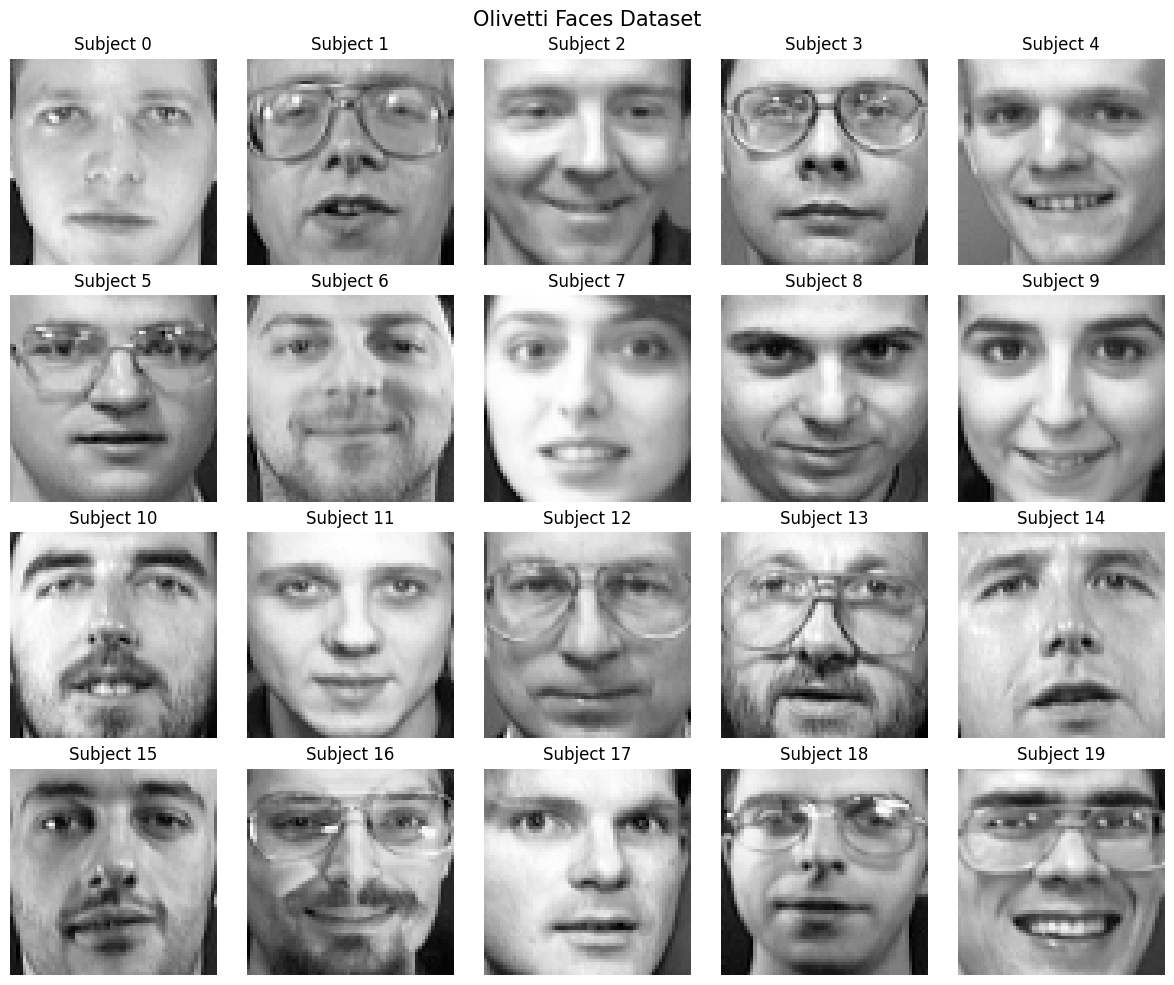

In [14]:
faces = fetch_olivetti_faces(shuffle=False)

X = faces.data
y = faces.target
images = faces.images

print("Total samples:", X.shape[0])
print("Unique subjects:", len(np.unique(y)))
print("Feature dimensions:", X.shape[1])
print("Image dimensions:", images.shape[1:])

# 20 sample faces
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    index = i * 10
    ax.imshow(images[index], cmap="gray")
    ax.set_title(f"Subject {y[index]}")
    ax.axis("off")

plt.suptitle("Olivetti Faces Dataset", fontsize=15)
plt.tight_layout()
plt.show()

# **Task 2:**
This uses PCA model to find out how many components are needed to keep most of the information in the facial images. It calculates how much variance each component explains and how the variance adds up when more components are added. The results show that 66 components are needed for 90% variance, 123 for 95%, and 260 for 99%.

Components for 90% variance: 66
Components for 95% variance: 123
Components for 99% variance: 260


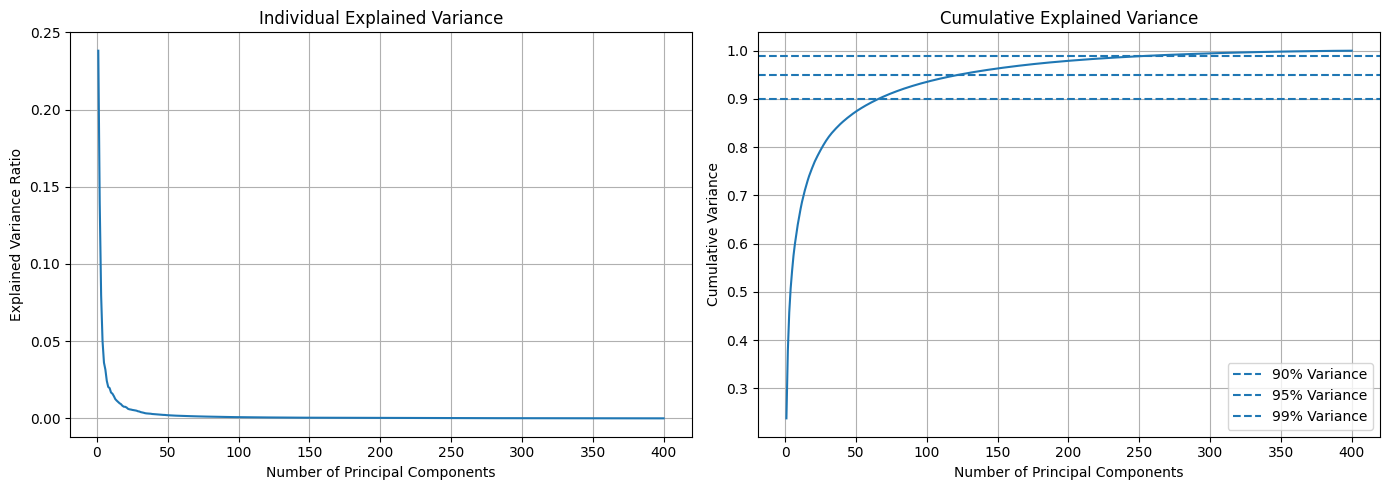

In [15]:
# Fit PCA
pca_full = PCA(svd_solver="full")
pca_full.fit(X)

#variance
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

k90 = np.searchsorted(cumulative_variance, 0.90) + 1
k95 = np.searchsorted(cumulative_variance, 0.95) + 1
k99 = np.searchsorted(cumulative_variance, 0.99) + 1

print("Components for 90% variance:", k90)
print("Components for 95% variance:", k95)
print("Components for 99% variance:", k99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, len(explained_variance) + 1),
    explained_variance
)
axes[0].set_title("Individual Explained Variance")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].grid(True)

axes[1].plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

for threshold in [0.90, 0.95, 0.99]:
    axes[1].axhline(
        threshold,
        linestyle="--",
        label=f"{int(threshold * 100)}% Variance"
    )

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# **Task 3: **

This chooses five facial images and uses PCA to reconstruct them with 10, 50, 100, 200, and 300 components. The reconstructed images are displayed next to the originals to show how the number of components affects the image quality. With 10 components, the faces keep their basic shape but lose a lot of their details. As more components are added, the faces become clearer and look more like the originals. The code also calculates Mean Squared Error and plots a graph showing how reconstruction error goes down when components are used


k = 10, MSE = 0.004633
k = 50, MSE = 0.002015
k = 100, MSE = 0.001103
k = 200, MSE = 0.000448
k = 300, MSE = 0.000124


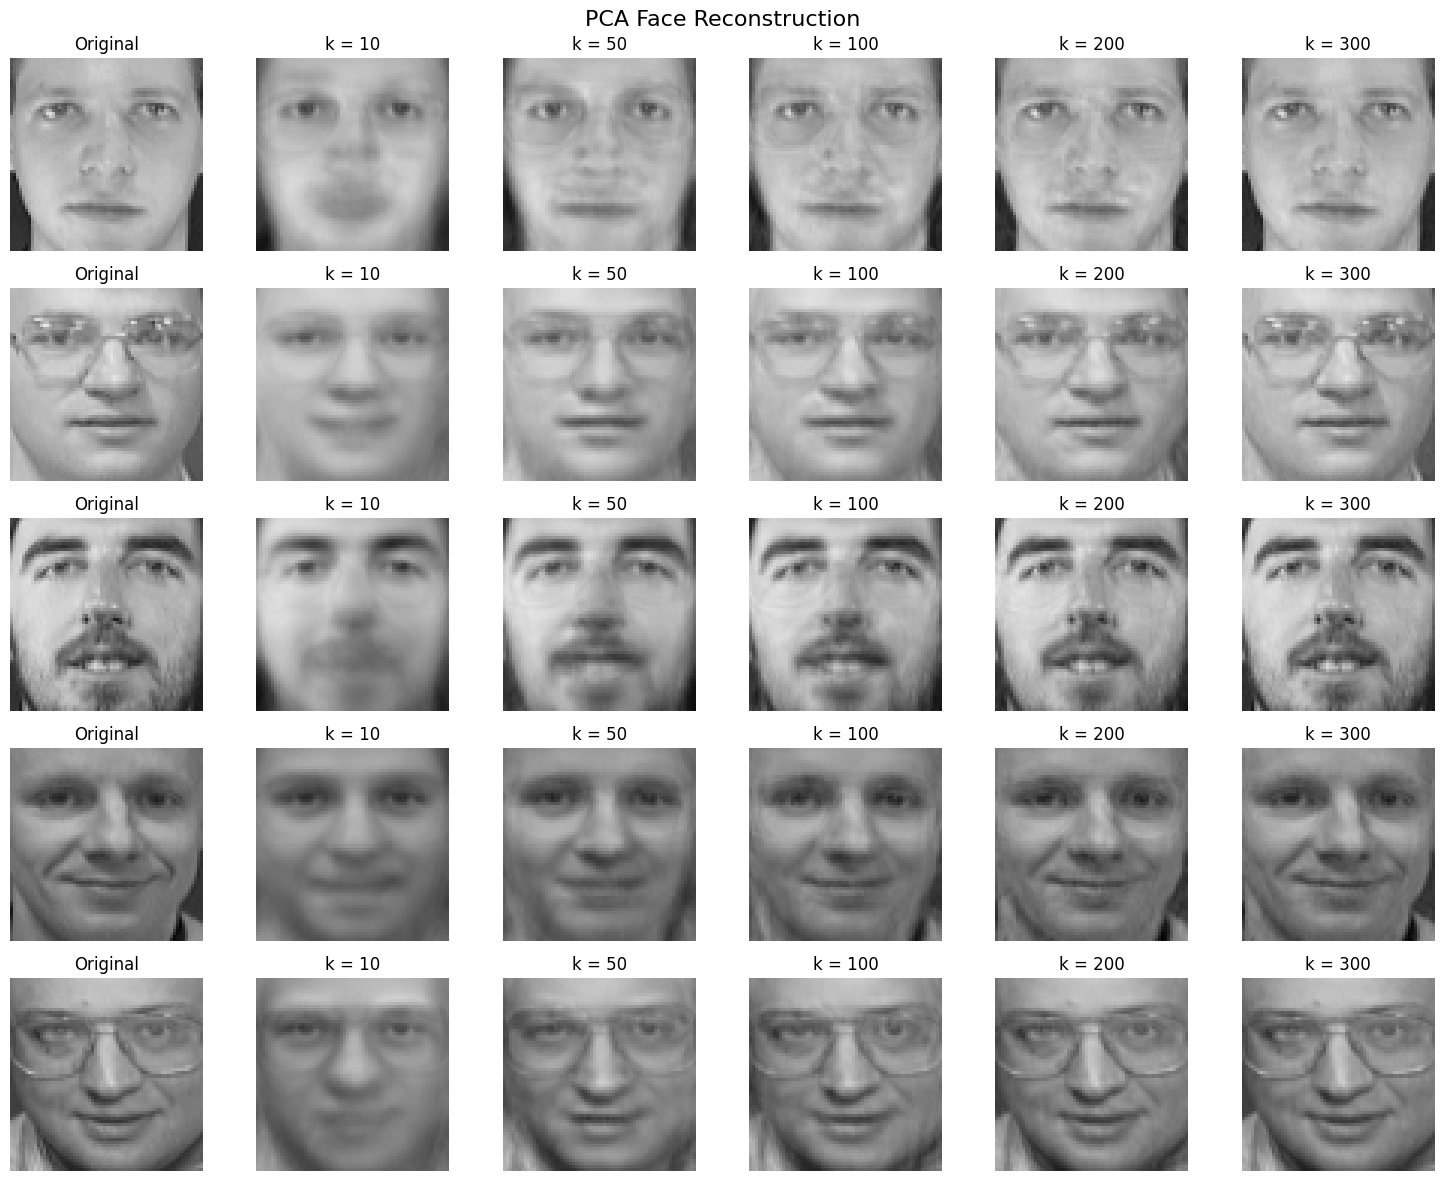

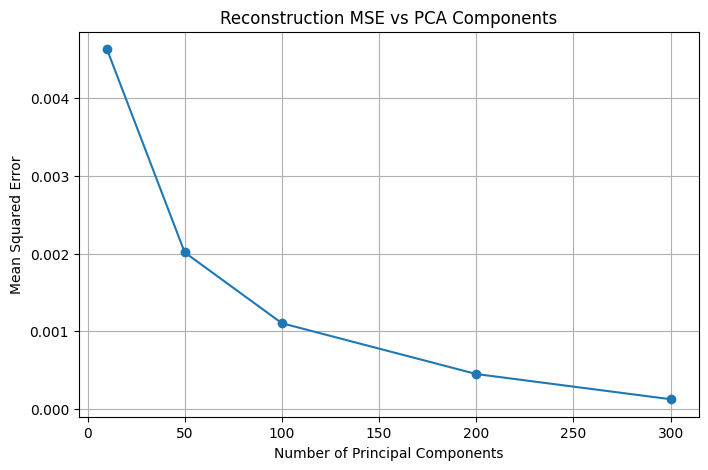

In [16]:
#five representative faces
selected_indices = [0, 50, 100, 200, 300]
original_faces = X[selected_indices]


k_values = [10, 50, 100, 200, 300]

mse_values = []

# Reconstruction grid
fig, axes = plt.subplots(
    len(selected_indices),
    len(k_values) + 1,
    figsize=(15, 12)
)

# Shows original faces
for i in range(len(selected_indices)):
    axes[i, 0].imshow(
        original_faces[i].reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")

# Reconstructs faces
for j, k in enumerate(k_values):

    pca_k = PCA(n_components=k, svd_solver="full")
    pca_k.fit(X)

    compressed = pca_k.transform(original_faces)
    reconstructed = pca_k.inverse_transform(compressed)

    mse = mean_squared_error(
        original_faces,
        reconstructed
    )
    mse_values.append(mse)

    print(f"k = {k}, MSE = {mse:.6f}")

    # Shows reconstructed faces
    for i in range(len(selected_indices)):
        axes[i, j + 1].imshow(
            reconstructed[i].reshape(64, 64),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[i, j + 1].set_title(f"k = {k}")
        axes[i, j + 1].axis("off")

plt.suptitle("PCA Face Reconstruction", fontsize=16)
plt.tight_layout()
plt.show()

# Plot MSE
plt.figure(figsize=(8, 5))

plt.plot(k_values, mse_values, marker="o")

plt.title("Reconstruction MSE vs PCA Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Squared Error")
plt.grid(True)

plt.show()

# **Task 4:**

This code takes the first 15 principal components from the PCA model and displays them as Eigenfaces in a 3x5 grid. Each Eigenface represents a different pattern which is shown in the facial images like the lighting and shadows. The code also shows the percentage of variance displayed by each Eigenface. The first Eigenface has 23.81% of the variance while the later ones are smaller.


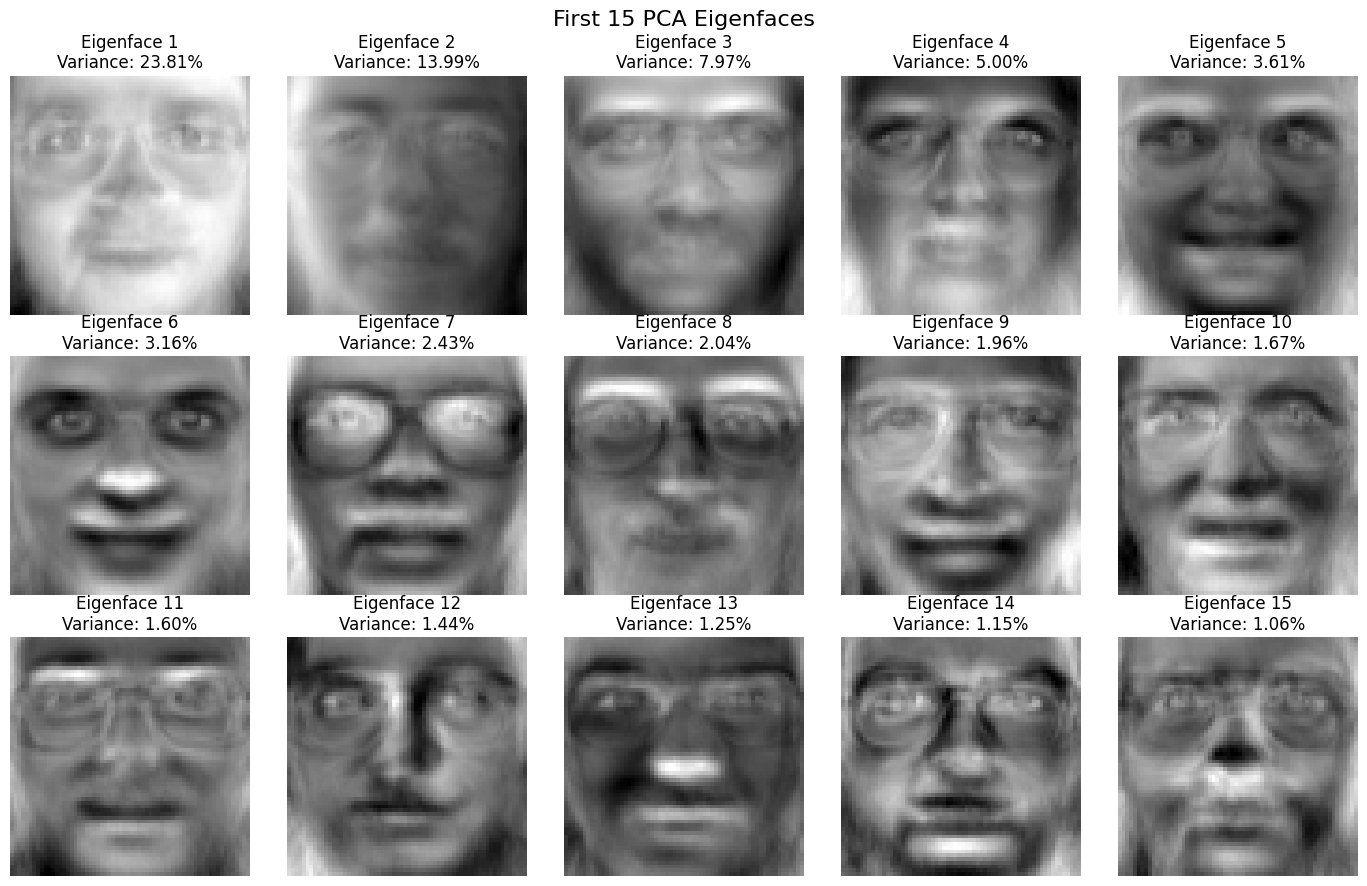

In [12]:
#The first 15 eigenfaces
eigenfaces = pca_full.components_[:15]

# Shows eigenfaces in a 3 x 5 grid
fig, axes = plt.subplots(3, 5, figsize=(14, 9))

for i, ax in enumerate(axes.flat):

    eigenface = eigenfaces[i].reshape(64, 64)

    ax.imshow(eigenface, cmap="gray")

    variance_percent = explained_variance[i] * 100

    ax.set_title(
        f"Eigenface {i + 1}\n"
        f"Variance: {variance_percent:.2f}%"
    )

    ax.axis("off")

plt.suptitle("First 15 PCA Eigenfaces", fontsize=16)
plt.tight_layout()
plt.show()

# **Task 5: **

This code splits the dataset into 80% training data and 20% testing data and then trains two Logistic Regression models. The first model uses all 4096 original features, while the second uses PCA to reduce the number of features while keeping 95% of the variance. Both models achieved 96.25% accuracy but the PCA model trained much faster and only took 0.62 seconds compared to 24.13 seconds. The graph looks at both for their accuracy and training time to show how reducing the number of features can make training faster

Logistic Regression (Raw Features)
Accuracy: 0.9625
Training Time: 22.1559 seconds

Logistic Regression (PCA Features)
Accuracy: 0.9625
Training Time: 0.5110 seconds

PCA Components: 111


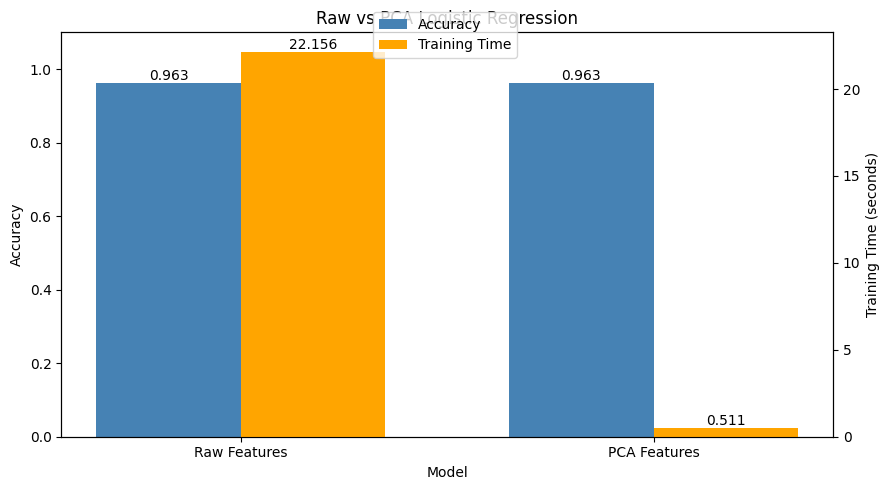

In [19]:
# Split dataset into both training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

log_raw = LogisticRegression(max_iter=2000)

start = time.perf_counter()
log_raw.fit(X_train, y_train)
raw_time = time.perf_counter() - start

raw_predictions = log_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_predictions)

log_pca = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("logistic", LogisticRegression(max_iter=2000))
])

start = time.perf_counter()
log_pca.fit(X_train, y_train)
pca_time = time.perf_counter() - start

pca_predictions = log_pca.predict(X_test)
pca_accuracy = accuracy_score(y_test, pca_predictions)

# Display results
print("Logistic Regression (Raw Features)")
print(f"Accuracy: {raw_accuracy:.4f}")
print(f"Training Time: {raw_time:.4f} seconds")

print("\nLogistic Regression (PCA Features)")
print(f"Accuracy: {pca_accuracy:.4f}")
print(f"Training Time: {pca_time:.4f} seconds")

print(
    "\nPCA Components:",
    log_pca.named_steps["pca"].n_components_
)

# Create dual-axis comparison plot
models = ["Raw Features", "PCA Features"]
accuracies = [raw_accuracy, pca_accuracy]
times = [raw_time, pca_time]

positions = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

bars1 = ax1.bar(
    positions - width / 2,
    accuracies,
    width,
    color="steelblue",
    label="Accuracy"
)

bars2 = ax2.bar(
    positions + width / 2,
    times,
    width,
    color="orange",
    label="Training Time"
)

ax1.set_ylabel("Accuracy")
ax2.set_ylabel("Training Time (seconds)")
ax1.set_xlabel("Model")
ax1.set_title("Raw vs PCA Logistic Regression")

ax1.set_xticks(positions)
ax1.set_xticklabels(models)
ax1.set_ylim(0, 1.1)

ax1.bar_label(bars1, fmt="%.3f")
ax2.bar_label(bars2, fmt="%.3f")

fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98))

plt.tight_layout()
plt.show()

# **Task 6: **

This code trains an SVM using an RBF kernel and PCA-reduced facial images. The RBF kernel makes the model be able to find more complicated patterns in the data. The model achieved 97.50% accuracy and took 0.287 seconds to train. The code also compares its predictions with Logistic Regression using two confusion matrices. These matrices show which ones were predicted correctly and where the models made mistakes

RBF Kernel SVM (PCA Features)
Accuracy: 0.9750
Training Time: 0.2853 seconds

PCA Logistic Regression Accuracy: 0.9625
RBF SVM Accuracy: 0.9750
Accuracy Difference: 1.25 percentage points


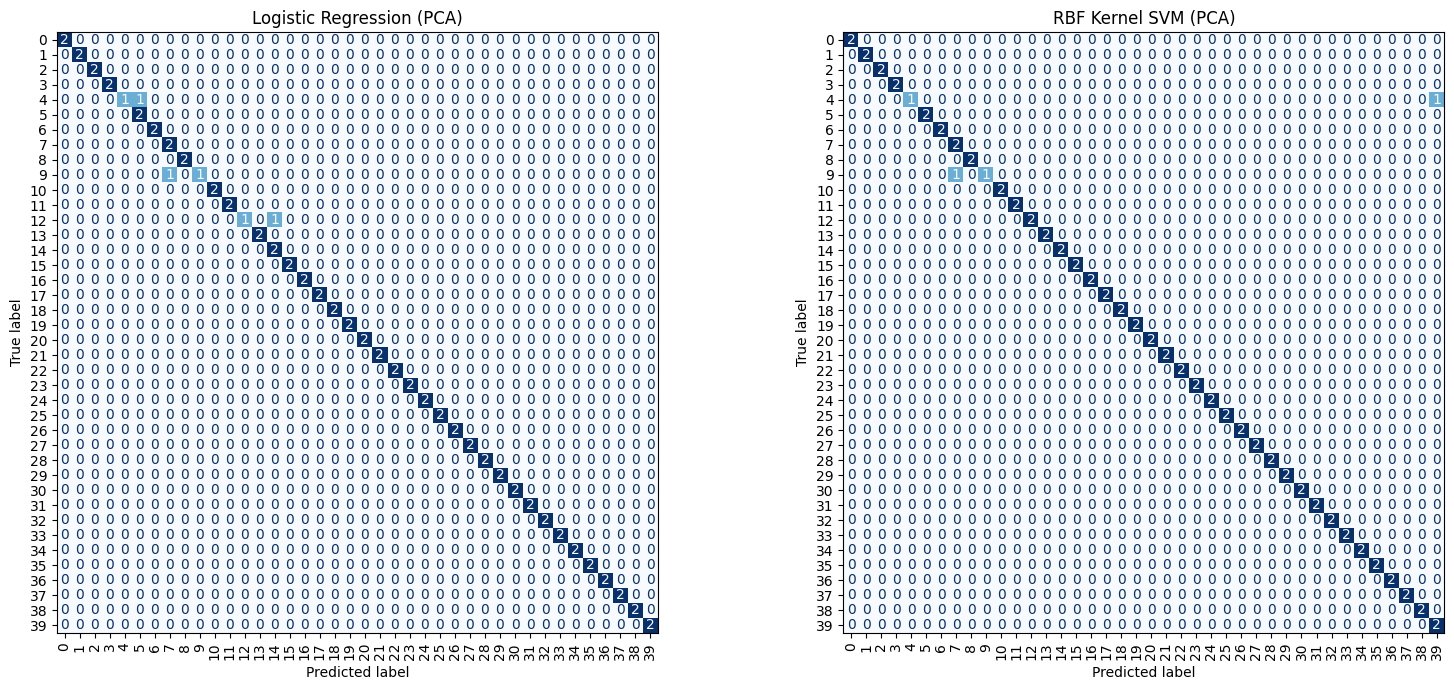

In [20]:
# Create PCA and RBF SVM pipeline
svm_pca = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("svm", SVC(kernel="rbf", C=10, gamma="scale"))
])

# Training SVM model
start = time.perf_counter()
svm_pca.fit(X_train, y_train)
svm_time = time.perf_counter() - start

svm_predictions = svm_pca.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("RBF Kernel SVM (PCA Features)")
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"Training Time: {svm_time:.4f} seconds")

print("\nPCA Logistic Regression Accuracy:", f"{pca_accuracy:.4f}")
print("RBF SVM Accuracy:", f"{svm_accuracy:.4f}")

print(
    "Accuracy Difference:",
    f"{(svm_accuracy - pca_accuracy) * 100:.2f} percentage points"
)

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pca_predictions,
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    xticks_rotation="vertical"
)

axes[0].set_title("Logistic Regression (PCA)")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    xticks_rotation="vertical"
)

axes[1].set_title("RBF Kernel SVM (PCA)")

plt.tight_layout()
plt.show()

Task 7:

This code creates a Voting Ensemble by combining three models. A Polynomial SVM, an RBF SVM, and a Random Forest with 100 trees. The models use PCA reduced features and combine all of their predictions to make a final decision. The ensemble has a 96.25% accuracy and took 1.33 seconds to train. This also creates a bar graph comparing the ensembles accuracy with Logistic Regression and the RBF SVM


Soft Voting Ensemble (PCA Features)
Accuracy: 0.9625
Training Time: 1.3630 seconds

Model Accuracy Comparison
Logistic Regression (PCA): 0.9625
RBF Kernel SVM (PCA): 0.9750
Voting Ensemble (PCA): 0.9625


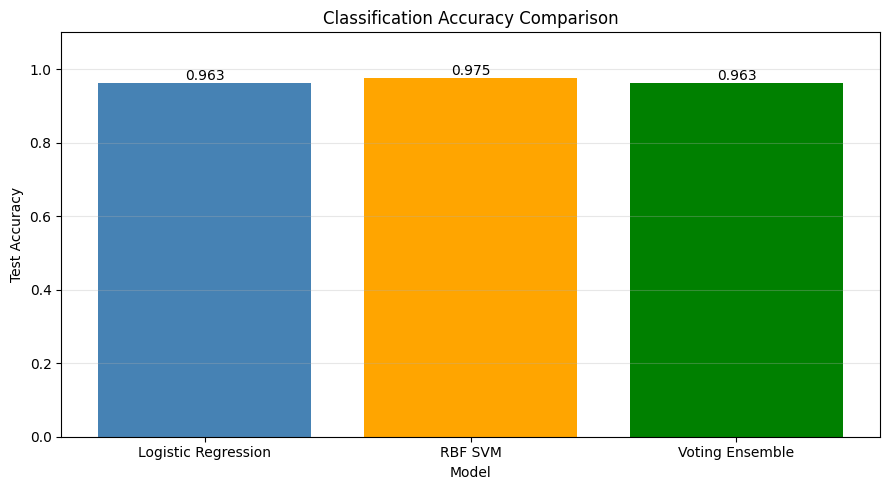

In [21]:
# Creating the ensemble classifiers
poly_svm = SVC(
    kernel="poly",
    degree=2,
    C=10,
    gamma="scale",
    probability=True,
    random_state=42
)

rbf_svm = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
voting = VotingClassifier(
    estimators=[
        ("poly_svm", poly_svm),
        ("rbf_svm", rbf_svm),
        ("random_forest", random_forest)
    ],
    voting="soft"
)

# Create PCA and VotingClassifier pipeline
ensemble_pca = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("ensemble", voting)
])

# Train ensemble
start = time.perf_counter()
ensemble_pca.fit(X_train, y_train)
ensemble_time = time.perf_counter() - start

ensemble_predictions = ensemble_pca.predict(X_test)

ensemble_accuracy = accuracy_score(
    y_test,
    ensemble_predictions
)

print("Soft Voting Ensemble (PCA Features)")
print(f"Accuracy: {ensemble_accuracy:.4f}")
print(f"Training Time: {ensemble_time:.4f} seconds")

# Compare models
print("\nModel Accuracy Comparison")
print(f"Logistic Regression (PCA): {pca_accuracy:.4f}")
print(f"RBF Kernel SVM (PCA): {svm_accuracy:.4f}")
print(f"Voting Ensemble (PCA): {ensemble_accuracy:.4f}")

model_names = [
    "Logistic Regression",
    "RBF SVM",
    "Voting Ensemble"
]

model_accuracies = [
    pca_accuracy,
    svm_accuracy,
    ensemble_accuracy
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    model_accuracies,
    color=["steelblue", "orange", "green"]
)

plt.bar_label(bars, fmt="%.3f")

plt.title("Classification Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# **Task 8:**
This code brings together the accuracy and training time results from all four of the classification models. It creates a table and a bar graph comparing Logistic Regression with raw features, Logistic Regression with PCA reducde, RBF SVM with PCA, and the Voting Ensemble with PCA. The graph has two different axes to show accuracy and training time. The results show that the RBF SVM had the highest accuracy at 97.50% and the fastest training time at 0.287 seconds. This makes it easier to compare the models and see which performed the best.

Final Model Comparison
                    Model  Accuracy  Training Time
Logistic Regression (Raw)    0.9625      24.127709
Logistic Regression (PCA)    0.9625       0.621554
            RBF SVM (PCA)    0.9750       0.287013
    Voting Ensemble (PCA)    0.9625       1.329049


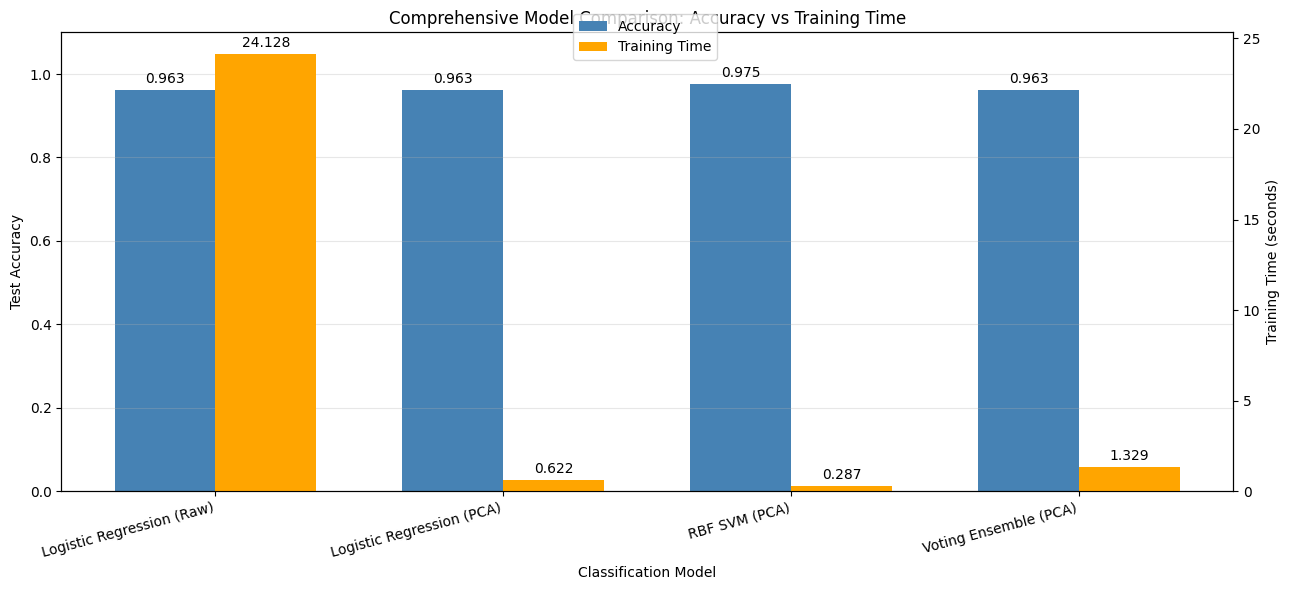


Best Accuracy:
RBF SVM (PCA)
Accuracy: 0.9750

Fastest Training Time:
RBF SVM (PCA)
Time: 0.2870 seconds


In [18]:
import pandas as pd

# Store results from all four models
results = pd.DataFrame({
    "Model": [
        "Logistic Regression (Raw)",
        "Logistic Regression (PCA)",
        "RBF SVM (PCA)",
        "Voting Ensemble (PCA)"
    ],
    "Accuracy": [
        raw_accuracy,
        pca_accuracy,
        svm_accuracy,
        ensemble_accuracy
    ],
    "Training Time": [
        raw_time,
        pca_time,
        svm_time,
        ensemble_time
    ]
})

print("Final Model Comparison")
print(results.to_string(index=False))

# Create dual-axis comparison chart
positions = np.arange(len(results))
width = 0.35

fig, ax1 = plt.subplots(figsize=(13, 6))
ax2 = ax1.twinx()

bars1 = ax1.bar(
    positions - width / 2,
    results["Accuracy"],
    width,
    color="steelblue",
    label="Accuracy"
)

# Training time bars
bars2 = ax2.bar(
    positions + width / 2,
    results["Training Time"],
    width,
    color="orange",
    label="Training Time"
)

ax1.bar_label(bars1, fmt="%.3f", padding=3)
ax2.bar_label(bars2, fmt="%.3f", padding=3)

ax1.set_xlabel("Classification Model")
ax1.set_ylabel("Test Accuracy")
ax2.set_ylabel("Training Time (seconds)")

ax1.set_title(
    "Comprehensive Model Comparison: Accuracy vs Training Time"
)

ax1.set_xticks(positions)
ax1.set_xticklabels(
    results["Model"],
    rotation=15,
    ha="right"
)

ax1.set_ylim(0, 1.1)
ax1.grid(axis="y", alpha=0.3)

fig.legend(
    [bars1, bars2],
    ["Accuracy", "Training Time"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98)
)

plt.tight_layout()
plt.show()

best_accuracy = results.loc[results["Accuracy"].idxmax()]
fastest_model = results.loc[results["Training Time"].idxmin()]

print("\nBest Accuracy:")
print(best_accuracy["Model"])
print(f"Accuracy: {best_accuracy['Accuracy']:.4f}")

print("\nFastest Training Time:")
print(fastest_model["Model"])
print(f"Time: {fastest_model['Training Time']:.4f} seconds")